In [9]:
import pandas as pd
import numpy as np
import seaborn as sns
import warnings
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

In [10]:
data = pd.read_csv('heart.csv')

# **EDA**

In [11]:
data.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [12]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [13]:
data.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [14]:
data.shape

(918, 12)

In [15]:
data.isnull().sum()

,0
Age,0
Sex,0
ChestPainType,0
RestingBP,0
Cholesterol,0
FastingBS,0
RestingECG,0
MaxHR,0
ExerciseAngina,0
Oldpeak,0


In [17]:
data.duplicated().sum()

np.int64(0)

In [19]:
data.columns

Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease'],
      dtype='object')

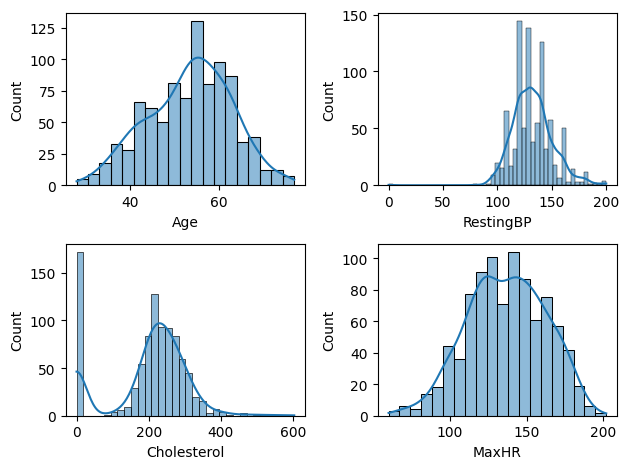

In [21]:
def plotting(var,num):
    plt.subplot(2,2,num)
    sns.histplot(data[var],kde = True)

plotting('Age',1)
plotting('RestingBP',2)
plotting('Cholesterol',3)
plotting('MaxHR',4)


plt.tight_layout()

In [22]:
data['Cholesterol'].value_counts()

,count
Cholesterol,
0,172
254,11
220,10
223,10
204,9
...,...
353,1
278,1
157,1


In [23]:
cholesterol_mean = data.loc[data['Cholesterol'] != 0,'Cholesterol'].mean()

In [25]:
data_cleaned = data

In [26]:
data_cleaned['Cholesterol'] = data_cleaned['Cholesterol'].replace(0 , cholesterol_mean)
data_cleaned['Cholesterol'] = data_cleaned['Cholesterol'].round(2)

In [28]:
resting_bp_mean = data_cleaned.loc[data_cleaned['RestingBP'] != 0,'RestingBP'].mean()

In [29]:
data_cleaned['RestingBP'] = data_cleaned['RestingBP'].replace(0 , resting_bp_mean)
data_cleaned['RestingBP'] = data_cleaned['RestingBP'].round(2)

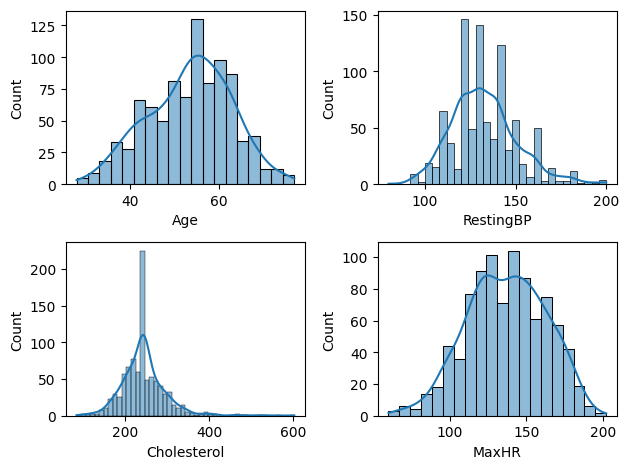

In [30]:
def plotting(var,num):
    plt.subplot(2,2,num)
    sns.histplot(data[var],kde = True)

plotting('Age',1)
plotting('RestingBP',2)
plotting('Cholesterol',3)
plotting('MaxHR',4)


plt.tight_layout()

<Axes: xlabel='Sex', ylabel='count'>

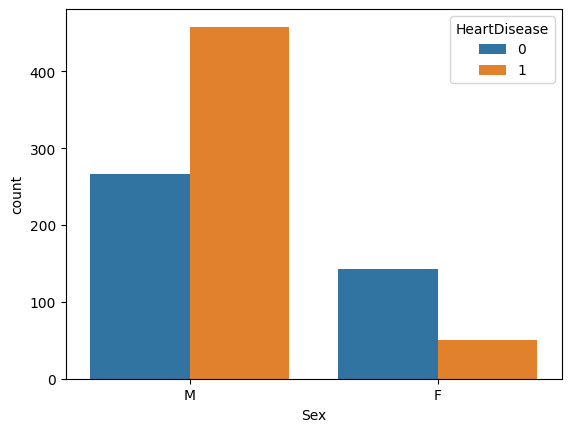

In [31]:
sns.countplot(x = data_cleaned['Sex'],hue = data_cleaned['HeartDisease'])

<Axes: xlabel='ChestPainType', ylabel='count'>

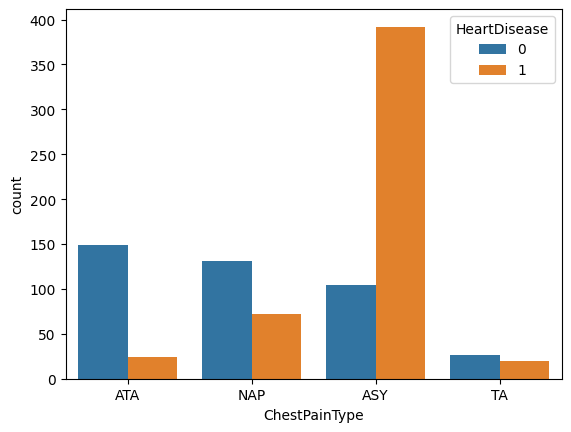

In [32]:
sns.countplot(x = data_cleaned['ChestPainType'],hue = data_cleaned['HeartDisease'])

In [33]:
data_cleaned.columns

Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease'],
      dtype='object')

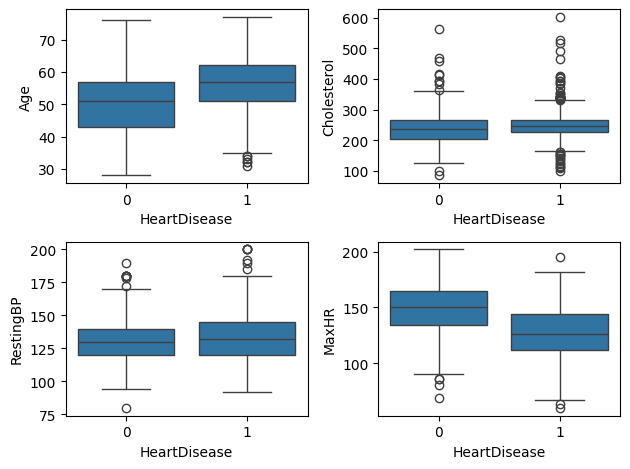

In [38]:
numeric_columns = ['Age', 'Cholesterol', 'RestingBP', 'MaxHR']
i = 1
def plotting(var,num):
    plt.subplot(2,2,num)
    sns.boxplot(data = data_cleaned, y = var , x = 'HeartDisease')

for col in numeric_columns:
  plotting(col , i)
  i += 1

plt.tight_layout()

<Axes: >

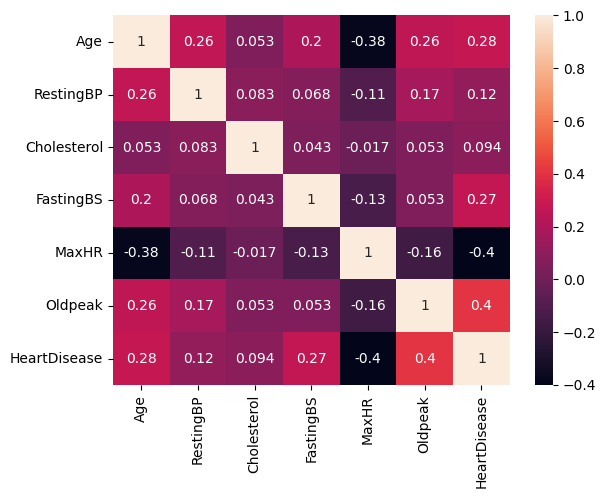

In [39]:
sns.heatmap(data_cleaned.corr(numeric_only = True) , annot = True)

# **Data Cleaning and Preprocessing**

In [40]:
data_cleaned = pd.get_dummies(data_cleaned)

In [43]:
data_cleaned = data_cleaned.astype(int)

In [44]:
data_cleaned

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_F,Sex_M,ChestPainType_ASY,...,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST,ExerciseAngina_N,ExerciseAngina_Y,ST_Slope_Down,ST_Slope_Flat,ST_Slope_Up
0,40,140,289,0,172,0,0,0,1,0,...,0,0,0,1,0,1,0,0,0,1
1,49,160,180,0,156,1,1,1,0,0,...,1,0,0,1,0,1,0,0,1,0
2,37,130,283,0,98,0,0,0,1,0,...,0,0,0,0,1,1,0,0,0,1
3,48,138,214,0,108,1,1,1,0,1,...,0,0,0,1,0,0,1,0,1,0
4,54,150,195,0,122,0,0,0,1,0,...,1,0,0,1,0,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,110,264,0,132,1,1,0,1,0,...,0,1,0,1,0,1,0,0,1,0
914,68,144,193,1,141,3,1,0,1,1,...,0,0,0,1,0,1,0,0,1,0
915,57,130,131,0,115,1,1,0,1,1,...,0,0,0,1,0,0,1,0,1,0
916,57,130,236,0,174,0,1,1,0,0,...,0,0,1,0,0,1,0,0,1,0


In [45]:
from sklearn.preprocessing import StandardScaler
cols = ['Age' , 'Cholesterol' , 'RestingBP' , 'MaxHR']
scaler = StandardScaler()

data_cleaned[cols] = scaler.fit_transform(data_cleaned[cols])

In [46]:
data_cleaned

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_F,Sex_M,ChestPainType_ASY,...,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST,ExerciseAngina_N,ExerciseAngina_Y,ST_Slope_Down,ST_Slope_Flat,ST_Slope_Up
0,-1.433140,0.414885,0.834754,0,1.382928,0,0,0,1,0,...,0,0,0,1,0,1,0,0,0,1
1,-0.478484,1.527224,-1.210675,0,0.754157,1,1,1,0,0,...,1,0,0,1,0,1,0,0,1,0
2,-1.751359,-0.141284,0.722161,0,-1.525138,0,0,0,1,0,...,0,0,0,0,1,1,0,0,0,1
3,-0.584556,0.303651,-0.572651,0,-1.132156,1,1,1,0,1,...,0,0,0,1,0,0,1,0,1,0
4,0.051881,0.971054,-0.929194,0,-0.581981,0,0,0,1,0,...,1,0,0,1,0,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,-0.902775,-1.253622,0.365619,0,-0.188999,1,1,0,1,0,...,0,1,0,1,0,1,0,0,1,0
914,1.536902,0.637353,-0.966725,1,0.164684,3,1,0,1,1,...,0,0,0,1,0,1,0,0,1,0
915,0.370100,-0.141284,-2.130180,0,-0.857069,1,1,0,1,1,...,0,0,0,1,0,0,1,0,1,0
916,0.370100,-0.141284,-0.159813,0,1.461525,0,1,1,0,0,...,0,0,1,0,0,1,0,0,1,0


# **Feature Engineering**

In [50]:
from scipy.stats import pearsonr

# ----------------------------------
# Pearson Correlation Calculation
# ----------------------------------

# List of features to check against target
selected_features = [
    'Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak',
       'HeartDisease', 'Sex_F', 'Sex_M', 'ChestPainType_ASY',
       'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA',
       'RestingECG_LVH', 'RestingECG_Normal', 'RestingECG_ST',
       'ExerciseAngina_N', 'ExerciseAngina_Y', 'ST_Slope_Down',
       'ST_Slope_Flat', 'ST_Slope_Up'
]

correlations = {
    feature: pearsonr(data_cleaned[feature], data_cleaned['HeartDisease'])[0]
    for feature in selected_features
}
correlation_df = pd.DataFrame(list(correlations.items()), columns=['Feature', 'Pearson Correlation'])
correlation_df.sort_values(by='Pearson Correlation', ascending=False)

,Feature,Pearson Correlation
6,HeartDisease,1.000000
19,ST_Slope_Flat,0.554134
9,ChestPainType_ASY,0.516716
17,ExerciseAngina_Y,0.494282
5,Oldpeak,0.392385
8,Sex_M,0.305445
0,Age,0.282039
3,FastingBS,0.267291
18,ST_Slope_Down,0.122527
1,RestingBP,0.117909


In [51]:
cat_features = [
    'Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak',
       'HeartDisease', 'Sex_F', 'Sex_M', 'ChestPainType_ASY',
       'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA',
       'RestingECG_LVH', 'RestingECG_Normal', 'RestingECG_ST',
       'ExerciseAngina_N', 'ExerciseAngina_Y', 'ST_Slope_Down',
       'ST_Slope_Flat', 'ST_Slope_Up'
]

In [53]:
from scipy.stats import chi2_contingency

alpha = 0.05

chi2_results = {}

for col in cat_features:
    # Skip checking the target variable against itself
    if col == 'HeartDisease':
        continue
    contingency = pd.crosstab(data_cleaned[col], data_cleaned['HeartDisease'])
    chi2_stat, p_val, _, _ = chi2_contingency(contingency)
    decision = 'Reject Null (Keep Feature)' if p_val < alpha else 'Accept Null (Drop Feature)'
    chi2_results[col] = {
        'chi2_statistic': chi2_stat,
        'p_value': p_val,
        'Decision': decision
    }

chi2_df = pd.DataFrame(chi2_results).T
chi2_df = chi2_df.sort_values(by='p_value')
chi2_df

,chi2_statistic,p_value,Decision
ST_Slope_Up,352.823905,0.0,Reject Null (Keep Feature)
ST_Slope_Flat,279.659914,0.0,Reject Null (Keep Feature)
ChestPainType_ASY,243.021138,0.0,Reject Null (Keep Feature)
ExerciseAngina_Y,222.259383,0.0,Reject Null (Keep Feature)
ExerciseAngina_N,222.259383,0.0,Reject Null (Keep Feature)
Oldpeak,182.849456,0.0,Reject Null (Keep Feature)
ChestPainType_ATA,146.236323,0.0,Reject Null (Keep Feature)
Sex_M,84.145101,0.0,Reject Null (Keep Feature)
Sex_F,84.145101,0.0,Reject Null (Keep Feature)
FastingBS,64.320679,0.0,Reject Null (Keep Feature)


In [54]:
data_cleaned.columns

Index(['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak',
       'HeartDisease', 'Sex_F', 'Sex_M', 'ChestPainType_ASY',
       'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA',
       'RestingECG_LVH', 'RestingECG_Normal', 'RestingECG_ST',
       'ExerciseAngina_N', 'ExerciseAngina_Y', 'ST_Slope_Down',
       'ST_Slope_Flat', 'ST_Slope_Up'],
      dtype='object')

In [56]:
final_data = data_cleaned[[
    'Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak',
    'HeartDisease', 'Sex_F', 'Sex_M', 'ChestPainType_ASY',
    'ChestPainType_ATA', 'ChestPainType_NAP', 'RestingECG_Normal', 'RestingECG_ST',
    'ExerciseAngina_N', 'ExerciseAngina_Y', 'ST_Slope_Down',
    'ST_Slope_Flat', 'ST_Slope_Up'
]]

In [57]:
final_data

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_F,Sex_M,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,RestingECG_Normal,RestingECG_ST,ExerciseAngina_N,ExerciseAngina_Y,ST_Slope_Down,ST_Slope_Flat,ST_Slope_Up
0,-1.433140,0.414885,0.834754,0,1.382928,0,0,0,1,0,1,0,1,0,1,0,0,0,1
1,-0.478484,1.527224,-1.210675,0,0.754157,1,1,1,0,0,0,1,1,0,1,0,0,1,0
2,-1.751359,-0.141284,0.722161,0,-1.525138,0,0,0,1,0,1,0,0,1,1,0,0,0,1
3,-0.584556,0.303651,-0.572651,0,-1.132156,1,1,1,0,1,0,0,1,0,0,1,0,1,0
4,0.051881,0.971054,-0.929194,0,-0.581981,0,0,0,1,0,0,1,1,0,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,-0.902775,-1.253622,0.365619,0,-0.188999,1,1,0,1,0,0,0,1,0,1,0,0,1,0
914,1.536902,0.637353,-0.966725,1,0.164684,3,1,0,1,1,0,0,1,0,1,0,0,1,0
915,0.370100,-0.141284,-2.130180,0,-0.857069,1,1,0,1,1,0,0,1,0,0,1,0,1,0
916,0.370100,-0.141284,-0.159813,0,1.461525,0,1,1,0,0,1,0,0,0,1,0,0,1,0
